# 03b — Bayesian analysis

Goal: a Bayesian treatment of the GBM parameters for both ETFs, alongside the frequentist estimates.

1. **Posterior of the GBM parameters** $(\nu_A, \nu_G, \sigma_A, \sigma_G, \rho)$ under a non-informative
   (Jeffreys) prior, sampled exactly from the conjugate posterior. Credible intervals are compared with the
   i.i.d. frequentist confidence intervals.
2. **Do the drifts differ?** Posterior probability that the global drift exceeds the Australian drift, and
   how that probability changes under a sceptical prior centred on "no difference".
3. **Posterior predictive check**: data simulated from the fitted GBM are compared with the observed data on
   statistics GBM is not designed to match (tails, skewness, volatility clustering).
4. **A fat-tailed alternative**: i.i.d. Student-$t$ log returns fitted by MCMC, compared with the normal
   (GBM) model by WAIC.

All parameters are under the real-world measure $\mathbb{P}$, in annual units with $\Delta t = 1/252$.
The notebook needs only `data/clean/log_returns.csv`; it saves posterior draws to
`data/clean/posterior_gbm.csv` for use in notebook 04.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import config as cfg
from src import gbm_utils as gu

gu.set_style()
pd.set_option("display.width", 140)
KEYS = list(cfg.TICKERS)
DT = cfg.DT
rng = np.random.default_rng(cfg.SEED)

daily = pd.read_csv(gu.CLEAN_DIR / "log_returns.csv", index_col="date", parse_dates=True)[KEYS]
X = daily.to_numpy()
n = len(X)
T_years = n * DT
print(f"n = {n} daily returns, T = {T_years:.2f} years")

n = 3029 daily returns, T = 12.02 years


## 1. Posterior of the GBM parameters

**Model.** Under GBM the daily log-return vectors are $X_k \overset{\text{iid}}{\sim} \mathcal{N}_2(m, V)$
with $m = \nu\,\Delta t$ and $V = \Sigma\,\Delta t$, where $\nu_i = \mu_i - \tfrac12\sigma_i^2$ and
$\Sigma$ has diagonal $\sigma_i^2$ and off-diagonal $\rho\,\sigma_A\sigma_G$.

**Prior.** Jeffreys prior $p(m, V) \propto |V|^{-3/2}$. It adds no information about the parameters, so no
parameter values are assumed.

**Posterior** (Gelman et al., *Bayesian Data Analysis*, 3rd ed., Sec. 3.6):

$$V \mid X \sim \text{Inv-Wishart}_{n-1}(S), \qquad m \mid V, X \sim \mathcal{N}_2\!\left(\bar X,\ V/n\right),
\qquad S = \sum_{k}(X_k - \bar X)(X_k - \bar X)^\top .$$

Draws are exact (no MCMC). Each draw is converted to annual units: $\nu = m/\Delta t$,
$\sigma_i = \sqrt{V_{ii}/\Delta t}$, $\rho = V_{12}/\sqrt{V_{11}V_{22}}$ and $\mu_i = \nu_i + \tfrac12\sigma_i^2$.

In [2]:
m_draw, V_draw = gu.gbm_posterior_draws(X, cfg.N_POST, rng)
post = pd.DataFrame({
    "nu_AU": m_draw[:, 0] / DT, "nu_GL": m_draw[:, 1] / DT,
    "sigma_AU": np.sqrt(V_draw[:, 0, 0] / DT), "sigma_GL": np.sqrt(V_draw[:, 1, 1] / DT),
    "rho": V_draw[:, 0, 1] / np.sqrt(V_draw[:, 0, 0] * V_draw[:, 1, 1]),
})
post["mu_AU"] = post.nu_AU + post.sigma_AU**2 / 2
post["mu_GL"] = post.nu_GL + post.sigma_GL**2 / 2
post["nu_GL - nu_AU"] = post.nu_GL - post.nu_AU
post["mu_GL - mu_AU"] = post.mu_GL - post.mu_AU

post[["nu_AU", "nu_GL", "sigma_AU", "sigma_GL", "rho"]].to_csv(
    gu.CLEAN_DIR / "posterior_gbm.csv", index=False, float_format="%.8f")
print(f"Saved {len(post)} posterior draws to data/clean/posterior_gbm.csv")

Saved 20000 posterior draws to data/clean/posterior_gbm.csv


**Frequentist comparison.** The i.i.d. 95% confidence intervals under GBM: $t$-interval for $\nu$ and for
the drift difference (from the daily differences $X^G_k - X^A_k$), $\chi^2$ interval for $\sigma$,
delta-method interval for $\mu = \nu + \tfrac12\sigma^2$, and Fisher-$z$ interval for $\rho$.

In [3]:
tq = stats.t.ppf(0.975, n - 1)
zq = stats.norm.ppf(0.975)
freq = {}
for i, k in enumerate(KEYS):
    x = X[:, i]
    nu_hat, s = x.mean() / DT, x.std(ddof=1)
    se_nu = s / np.sqrt(n) / DT
    sig_hat = s / np.sqrt(DT)
    sig_lo = np.sqrt((n - 1) * s**2 / stats.chi2.ppf(0.975, n - 1) / DT)
    sig_hi = np.sqrt((n - 1) * s**2 / stats.chi2.ppf(0.025, n - 1) / DT)
    mu_hat = nu_hat + sig_hat**2 / 2
    se_mu = np.sqrt(se_nu**2 + sig_hat**4 / (2 * (n - 1)))          # Var(sigma^2/2) = sigma^4 / (2(n-1))
    freq[f"nu_{k}"] = (nu_hat, nu_hat - tq * se_nu, nu_hat + tq * se_nu)
    freq[f"mu_{k}"] = (mu_hat, mu_hat - zq * se_mu, mu_hat + zq * se_mu)
    freq[f"sigma_{k}"] = (sig_hat, sig_lo, sig_hi)
r = np.corrcoef(X.T)[0, 1]
freq["rho"] = (r, np.tanh(np.arctanh(r) - zq / np.sqrt(n - 3)), np.tanh(np.arctanh(r) + zq / np.sqrt(n - 3)))
d = X[:, 1] - X[:, 0]
d_hat, se_d = d.mean() / DT, d.std(ddof=1) / np.sqrt(n) / DT
freq["nu_GL - nu_AU"] = (d_hat, d_hat - tq * se_d, d_hat + tq * se_d)

PARAMS = ["nu_AU", "nu_GL", "mu_AU", "mu_GL", "sigma_AU", "sigma_GL", "rho", "nu_GL - nu_AU"]
bayes_tab = pd.DataFrame({
    "posterior mean": post[PARAMS].mean(),
    "posterior sd": post[PARAMS].std(),
    "95% CrI low": post[PARAMS].quantile(0.025),
    "95% CrI high": post[PARAMS].quantile(0.975),
    "freq. estimate": [freq[p][0] for p in PARAMS],
    "95% CI low": [freq[p][1] for p in PARAMS],
    "95% CI high": [freq[p][2] for p in PARAMS],
}).rename_axis("parameter")
gu.TAB_DIR.mkdir(parents=True, exist_ok=True)
bayes_tab.to_csv(gu.TAB_DIR / "bayes_estimates.csv")

pct = [p for p in PARAMS if p != "rho"]
tex = bayes_tab.copy()
tex.loc[pct] = 100 * tex.loc[pct]
tex = tex.drop(columns="posterior sd")
tex.index = [r"$\nu_A$", r"$\nu_G$", r"$\mu_A$", r"$\mu_G$", r"$\sigma_A$", r"$\sigma_G$", r"$\rho$",
             r"$\nu_G-\nu_A$"]
tex.to_latex(gu.TAB_DIR / "bayes_estimates.tex", float_format="%.2f", escape=False,
             caption=("Posterior means and 95\\% equal-tailed credible intervals (Jeffreys prior) against "
                      "i.i.d.\\ frequentist estimates and 95\\% confidence intervals. Drifts and volatilities "
                      "in \\% per year; $\\rho$ unitless."),
             label="tab:bayes")
bayes_tab.style.format("{:.4f}")

,posterior mean,posterior sd,95% CrI low,95% CrI high,freq. estimate,95% CI low,95% CI high
parameter,,,,,,,
nu_AU,0.0818,0.0418,-0.0001,0.1642,0.0812,-0.0017,0.1640
nu_GL,0.1227,0.0377,0.0477,0.1958,0.1225,0.0482,0.1967
mu_AU,0.0925,0.0418,0.0107,0.1750,0.0919,0.0091,0.1748
mu_GL,0.1313,0.0377,0.0563,0.2044,0.1311,0.0569,0.2053
sigma_AU,0.1466,0.0019,0.1430,0.1504,0.1465,0.1429,0.1503
sigma_GL,0.1314,0.0017,0.1281,0.1347,0.1313,0.1281,0.1347
rho,0.5855,0.0120,0.5619,0.6082,0.5855,0.5616,0.6084
nu_GL - nu_AU,0.0409,0.0365,-0.0309,0.1117,0.0413,-0.0306,0.1133


In [4]:
probs = {
    "P(nu_AU > 0)": (post.nu_AU > 0).mean(),
    "P(nu_GL > 0)": (post.nu_GL > 0).mean(),
    "P(nu_GL > nu_AU)": (post["nu_GL - nu_AU"] > 0).mean(),
    "P(mu_GL > mu_AU)": (post["mu_GL - mu_AU"] > 0).mean(),
    "P(sigma_AU > sigma_GL)": (post.sigma_AU > post.sigma_GL).mean(),
}
for k, v in probs.items():
    print(f"{k:24s} = {v:.3f}")
ratio = post[["nu_AU", "nu_GL"]].std().to_numpy() / post[["sigma_AU", "sigma_GL"]].std().to_numpy()
print(f"\nPosterior sd of nu / posterior sd of sigma: AU {ratio[0]:.1f}, GL {ratio[1]:.1f}")

P(nu_AU > 0)             = 0.975
P(nu_GL > 0)             = 0.999
P(nu_GL > nu_AU)         = 0.869
P(mu_GL > mu_AU)         = 0.857
P(sigma_AU > sigma_GL)   = 1.000

Posterior sd of nu / posterior sd of sigma: AU 22.1, GL 22.4


**Fig B1** shows the marginal posterior densities of the drifts $\mu$ (left), the volatilities $\sigma$
(centre) and the correlation $\rho$ (right). The horizontal scales of the left and centre panels are equal in
width, so the spread of the two posteriors can be compared directly.

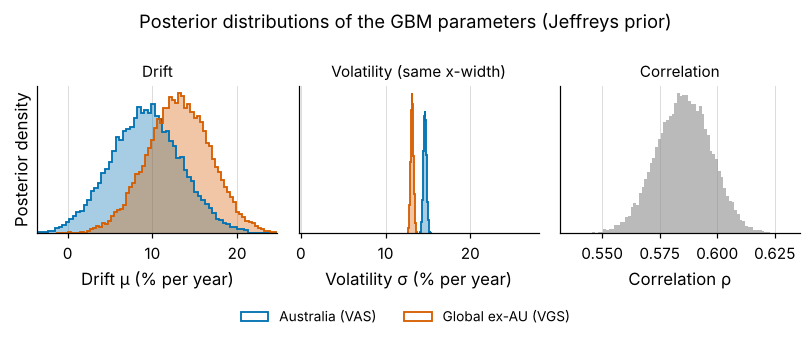

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(7.5, 3.0))
bins = 80
for k in KEYS:
    axes[0].hist(100 * post[f"mu_{k}"], bins=bins, density=True, histtype="stepfilled", alpha=0.35,
                 color=cfg.COLORS[k], lw=0)
    axes[0].hist(100 * post[f"mu_{k}"], bins=bins, density=True, histtype="step", color=cfg.COLORS[k],
                 lw=1.2, label=cfg.LABELS[k])
    axes[1].hist(100 * post[f"sigma_{k}"], bins=bins, density=True, histtype="stepfilled", alpha=0.35,
                 color=cfg.COLORS[k], lw=0)
    axes[1].hist(100 * post[f"sigma_{k}"], bins=bins, density=True, histtype="step", color=cfg.COLORS[k],
                 lw=1.2)
axes[2].hist(post.rho, bins=bins, density=True, histtype="stepfilled", color="0.55", alpha=0.6, lw=0)

lo, hi = np.percentile(100 * post[["mu_AU", "mu_GL"]].to_numpy(), [0.05, 99.95])
width = hi - lo
c = 100 * post[["sigma_AU", "sigma_GL"]].to_numpy().mean()
axes[0].set_xlim(lo, hi)
axes[1].set_xlim(c - width / 2, c + width / 2)
axes[0].set_xlabel("Drift μ (% per year)")
axes[1].set_xlabel("Volatility σ (% per year)")
axes[2].set_xlabel("Correlation ρ")
axes[0].set_ylabel("Posterior density")
for ax in axes:
    ax.set_yticks([])
axes[0].set_title("Drift", fontsize=10)
axes[1].set_title("Volatility (same x-width)", fontsize=10)
axes[2].set_title("Correlation", fontsize=10)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Posterior distributions of the GBM parameters (Jeffreys prior)", fontsize=12)
fig.tight_layout(rect=(0, 0.08, 1, 1))
gu.savefig(fig, "figB1_posteriors")
plt.show()

## 2. Do the Australian and global drifts differ?

Under the Jeffreys prior the posterior of $\delta = \nu_G - \nu_A$ is essentially
$\mathcal{N}(\hat\delta, s_\delta^2)$. A **sceptical prior** $\delta \sim \mathcal{N}(0, \tau^2)$ expresses the
belief that the drifts are equal, with $\tau$ the typical size of a difference considered plausible before
seeing the data. Combining it with the normal likelihood approximation gives

$$\delta \mid X \sim \mathcal{N}\!\left(\frac{\tau^2}{\tau^2 + s_\delta^2}\,\hat\delta,\ \frac{\tau^2 s_\delta^2}{\tau^2 + s_\delta^2}\right).$$

No single $\tau$ is assumed: the posterior probability $\mathbb{P}(\delta > 0 \mid X)$ is shown for a range of
$\tau$ from 0.25% to 20% per year. Large $\tau$ recovers the Jeffreys result.

**Fig B2**: left, posterior density of $\delta$ under the Jeffreys prior with the region $\delta > 0$ shaded;
right, $\mathbb{P}(\delta > 0 \mid X)$ against $\tau$ (log scale).

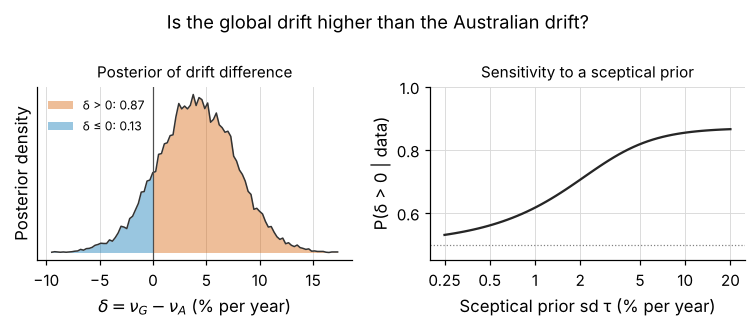

Jeffreys: posterior mean of delta = 4.09%/yr, sd = 3.65%/yr, P(delta > 0) = 0.869
tau = 1.03%: posterior mean 0.30%/yr, P(delta > 0) = 0.619
tau = 2.00%: posterior mean 0.95%/yr, P(delta > 0) = 0.705
tau = 4.88%: posterior mean 2.63%/yr, P(delta > 0) = 0.816


In [6]:
delta = post["nu_GL - nu_AU"]
d_hat, s_d = delta.mean(), delta.std()
taus = np.geomspace(0.0025, 0.20, 60)
shrink = taus**2 / (taus**2 + s_d**2)
post_mean = shrink * d_hat
post_sd = np.sqrt(taus**2 * s_d**2 / (taus**2 + s_d**2))
p_pos = stats.norm.cdf(post_mean / post_sd)
scept = pd.DataFrame({"tau": taus, "posterior mean": post_mean, "posterior sd": post_sd, "P(delta>0)": p_pos})
scept.to_csv(gu.TAB_DIR / "bayes_sceptical_prior.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0))
ax = axes[0]
dens, edges = np.histogram(100 * delta, bins=100, density=True)
mid = (edges[:-1] + edges[1:]) / 2
mid_ = np.sort(np.append(mid, 0.0))                 # add x = 0 so the two shaded regions meet
dens, mid = np.interp(mid_, mid, dens), mid_
ax.fill_between(mid, dens, where=mid >= 0, color=cfg.COLORS["GL"], alpha=0.4, lw=0,
                label=f"δ > 0: {(delta > 0).mean():.2f}")
ax.fill_between(mid, dens, where=mid <= 0, color=cfg.COLORS["AU"], alpha=0.4, lw=0,
                label=f"δ ≤ 0: {(delta <= 0).mean():.2f}")
ax.plot(mid, dens, color="0.2", lw=1)
ax.axvline(0, color="0.3", lw=0.8)
ax.set_xlabel(r"$\delta = \nu_G - \nu_A$ (% per year)")
ax.set_ylabel("Posterior density")
ax.set_yticks([])
ax.set_title("Posterior of drift difference", fontsize=10)
ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
ax.plot(100 * taus, p_pos, color="0.15", lw=1.5, label="P(δ > 0 | data)")
ax.axhline(0.5, color="0.5", lw=0.8, ls=":")
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 5, 10, 20])
ax.set_xticklabels(["0.25", "0.5", "1", "2", "5", "10", "20"])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_ylim(0.45, 1)
ax.set_xlabel("Sceptical prior sd τ (% per year)")
ax.set_ylabel("P(δ > 0 | data)")
ax.set_title("Sensitivity to a sceptical prior", fontsize=10)
fig.suptitle("Is the global drift higher than the Australian drift?", fontsize=12)
fig.tight_layout()
gu.savefig(fig, "figB2_drift_difference")
plt.show()

print(f"Jeffreys: posterior mean of delta = {d_hat:.2%}/yr, sd = {s_d:.2%}/yr, P(delta > 0) = {(delta > 0).mean():.3f}")
for t in [0.01, 0.02, 0.05]:
    i = np.argmin(abs(taus - t))
    print(f"tau = {taus[i]:.2%}: posterior mean {post_mean[i]:.2%}/yr, P(delta > 0) = {p_pos[i]:.3f}")

## 3. Posterior predictive check of GBM

For each of 2,000 posterior draws, a replicated sample of $n$ bivariate daily returns is simulated from GBM
with those parameters. Four statistics are computed on each replicate and on the observed data: excess
kurtosis, skewness, the number of days beyond 4 sample standard deviations, and the lag-1 autocorrelation of
squared returns (volatility clustering). The posterior predictive p-value is the share of replicates at least
as extreme as the data, in the direction of the observed departure.

**Fig B3** shows the distribution of each statistic across replicates (one histogram per ETF) with the
observed values as vertical lines.

In [7]:
idx = rng.choice(cfg.N_POST, cfg.N_PPC, replace=False)
L = np.linalg.cholesky(V_draw[idx])                                     # (N_PPC, 2, 2)
rep = m_draw[idx, None, :] + np.einsum("sij,stj->sti", L, rng.standard_normal((cfg.N_PPC, n, 2)))


def ppc_stats(x):
    # x: (..., n) -> dict of statistics over the last axis
    d = x - x.mean(axis=-1, keepdims=True)
    sd = d.std(axis=-1, ddof=1, keepdims=True)
    z = d / sd
    sq = x**2 - (x**2).mean(axis=-1, keepdims=True)
    return {
        "excess kurtosis": stats.kurtosis(x, axis=-1, bias=False),
        "skewness": stats.skew(x, axis=-1, bias=False),
        "days beyond 4 sd": (np.abs(z) > 4).sum(axis=-1),
        "lag-1 ACF of squares": (sq[..., 1:] * sq[..., :-1]).sum(axis=-1) / (sq**2).sum(axis=-1),
    }


STATS = ["excess kurtosis", "skewness", "days beyond 4 sd", "lag-1 ACF of squares"]
ppc_rows = []
reps, obs = {}, {}
for i, k in enumerate(KEYS):
    reps[k] = ppc_stats(rep[:, :, i])
    obs[k] = {s: float(v) for s, v in ppc_stats(X[:, i]).items()}
    for s in STATS:
        r_, o = reps[k][s], obs[k][s]
        p = (r_ <= o).mean() if s == "skewness" else (r_ >= o).mean()
        ppc_rows.append({"ETF": k, "statistic": s, "observed": o, "replicated median": np.median(r_),
                         "replicated 2.5%": np.quantile(r_, 0.025), "replicated 97.5%": np.quantile(r_, 0.975),
                         "posterior predictive p": p})
ppc_tab = pd.DataFrame(ppc_rows).set_index(["ETF", "statistic"])
ppc_tab.to_csv(gu.TAB_DIR / "bayes_ppc.csv")
del rep
print(f"A posterior predictive p of 0 means none of the {cfg.N_PPC} replicates was as extreme (p < {1 / cfg.N_PPC:.4f}).")
ppc_tab.style.format("{:.3f}")

A posterior predictive p of 0 means none of the 2000 replicates was as extreme (p < 0.0005).


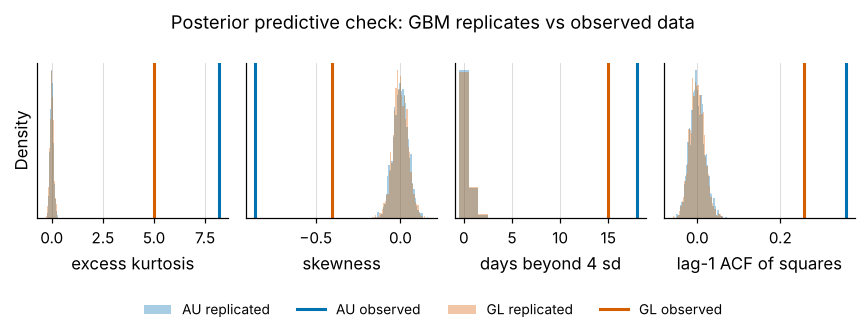

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(8.0, 2.9))
for ax, s in zip(axes, STATS):
    lo = min(min(reps[k][s].min(), obs[k][s]) for k in KEYS)
    hi = max(max(reps[k][s].max(), obs[k][s]) for k in KEYS)
    for k in KEYS:
        if s == "days beyond 4 sd":
            b = np.arange(-0.5, max(reps[k][s].max(), 3) + 1.5)
        else:
            b = np.linspace(reps[k][s].min(), reps[k][s].max(), 40)
        ax.hist(reps[k][s], bins=b, density=True, color=cfg.COLORS[k], alpha=0.35, lw=0,
                label=f"{k} replicated")
        ax.axvline(obs[k][s], color=cfg.COLORS[k], lw=2, label=f"{k} observed")
    pad = 0.05 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_yticks([])
    ax.set_xlabel(s)
axes[0].set_ylabel("Density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Posterior predictive check: GBM replicates vs observed data", fontsize=12)
fig.tight_layout(rect=(0, 0.1, 1, 1))
gu.savefig(fig, "figB3_ppc")
plt.show()

## 4. A fat-tailed alternative: Student-$t$ log returns

Model for each ETF separately: $X_k = a + s\,\varepsilon_k$ with $\varepsilon_k \overset{\text{iid}}{\sim} t_{\text{df}}$.
The normal (GBM) model is the limit df $\to \infty$. The model is still i.i.d., so it addresses the tails
but not volatility clustering.

**Priors:** flat on $a$; $p(s) \propto 1/s$; df $\sim$ Gamma(shape 2, rate 0.1) (Juárez and Steel, 2010),
which has mean 20 and puts substantial weight on large df (near-normal).

**Sampler:** random-walk Metropolis on $(a, \log s, \log \text{df})$. A pilot run sets the proposal
covariance; then 4 chains are started from dispersed pilot draws. Convergence is checked with split-$\hat R$
(should be below 1.01) and the effective sample size.

**Model comparison:** WAIC (Watanabe, 2010) for the normal and Student-$t$ models, on the deviance scale
(lower is better), with the standard error of the difference from the pointwise contributions.

In [9]:
a_prior, b_prior = cfg.T_DF_PRIOR
mcmc, diag_rows = {}, []
for i, k in enumerate(KEYS):
    x = X[:, i]
    lp = lambda th, x=x: gu.t_log_posterior(th, x, a_prior, b_prior)
    df0, a0, s0 = stats.t.fit(x)
    start = np.array([a0, np.log(s0), np.log(df0)])
    pilot, _ = gu.metropolis(lp, start, np.diag([s0 / np.sqrt(n) * 1.5, 0.03, 0.1]) ** 2, 3000, rng)
    cov = np.cov(pilot[1000:].T) * 2.38**2 / 3
    chains, accs = [], []
    for c in range(cfg.MCMC_CHAINS):
        draws, acc = gu.metropolis(lp, pilot[rng.integers(1000, 3000)], cov, cfg.MCMC_ITER, rng)
        chains.append(draws[cfg.MCMC_BURN:])
        accs.append(acc)
    chains = np.array(chains)                          # (chains, draws, 3)
    mcmc[k] = chains
    for j, name in enumerate(["a", "log s", "log df"]):
        diag_rows.append({"ETF": k, "parameter": name, "split R-hat": gu.split_rhat(chains[..., j]),
                          "ESS": gu.ess(chains[..., j]), "acceptance": np.mean(accs)})
diag = pd.DataFrame(diag_rows).set_index(["ETF", "parameter"])
print(f"Max split R-hat: {diag['split R-hat'].max():.4f}; min ESS: {diag['ESS'].min():.0f}")
diag.round(3)

Max split R-hat: 1.0020; min ESS: 1653


split R-hat       ESS  acceptance
ETF parameter                                   
AU  a                1.001  1890.242       0.297
    log s            1.001  1852.625       0.297
    log df           1.002  1821.199       0.297
GL  a                1.001  2039.767       0.336
    log s            1.000  1653.214       0.336
    log df           1.001  1871.860       0.336

In [10]:
t_rows = []
for k in KEYS:
    ch = mcmc[k].reshape(-1, 3)
    a, s, dfv = ch[:, 0], np.exp(ch[:, 1]), np.exp(ch[:, 2])
    ok = dfv > 2
    sig_t = s[ok] * np.sqrt(dfv[ok] / (dfv[ok] - 2)) / np.sqrt(DT)
    for name, v in [("df", dfv), ("nu (% per year)", 100 * a / DT), ("sigma (% per year)", 100 * sig_t)]:
        t_rows.append({"ETF": k, "parameter": name, "posterior median": np.median(v),
                       "95% CrI low": np.quantile(v, 0.025), "95% CrI high": np.quantile(v, 0.975)})
    print(f"{k}: share of draws with df > 2 (finite variance): {ok.mean():.3f}")
t_tab = pd.DataFrame(t_rows).set_index(["ETF", "parameter"])
t_tab.round(3)

AU: share of draws with df > 2 (finite variance): 1.000
GL: share of draws with df > 2 (finite variance): 1.000


posterior median  95% CrI low  95% CrI high
ETF parameter                                                      
AU  df                             3.937        3.421         4.587
    nu (% per year)               18.550       11.512        25.479
    sigma (% per year)            14.602       13.882        15.577
GL  df                             4.459        3.825         5.272
    nu (% per year)               16.965       10.529        23.269
    sigma (% per year)            13.092       12.543        13.813

In [11]:
S_W = 4000
cmp_rows = []
for i, k in enumerate(KEYS):
    x = X[:, i]
    j = rng.choice(cfg.N_POST, S_W, replace=False)
    ll_norm = stats.norm.logpdf(x[None, :], m_draw[j, i][:, None], np.sqrt(V_draw[j, i, i])[:, None])
    ch = mcmc[k].reshape(-1, 3)[rng.choice(mcmc[k].shape[0] * mcmc[k].shape[1], S_W, replace=False)]
    ll_t = stats.t.logpdf(x[None, :], np.exp(ch[:, 2])[:, None], ch[:, 0][:, None], np.exp(ch[:, 1])[:, None])
    w_n, p_n = gu.waic(ll_norm)
    w_t, p_t = gu.waic(ll_t)
    diff = p_n - p_t
    cmp_rows.append({"ETF": k, "WAIC normal (GBM)": w_n, "WAIC Student-t": w_t,
                     "difference (normal - t)": diff.sum(), "SE of difference": np.sqrt(n * diff.var())})
cmp = pd.DataFrame(cmp_rows).set_index("ETF")
cmp = cmp.join(t_tab.xs("df", level="parameter").add_prefix("df "))
cmp.to_csv(gu.TAB_DIR / "bayes_model_comparison.csv")
cmp.to_latex(gu.TAB_DIR / "bayes_model_comparison.tex", float_format="%.1f",
             caption=("WAIC (deviance scale, lower is better) for i.i.d.\\ normal (GBM) and Student-$t$ daily log "
                      "returns, and the posterior of the $t$ degrees of freedom (median, 95\\% CrI)."),
             label="tab:waic")
cmp.round(2)

,WAIC normal (GBM),WAIC Student-t,difference (normal - t),SE of difference,df posterior median,df 95% CrI low,df 95% CrI high
ETF,,,,,,,
AU,-19779.46,-20332.76,553.30,112.04,3.94,3.42,4.59
GL,-20446.18,-20845.17,398.99,75.09,4.46,3.82,5.27


**Fig B4** shows the posterior of the Student-$t$ degrees of freedom for each ETF. The normal distribution
(GBM) corresponds to df $\to \infty$.

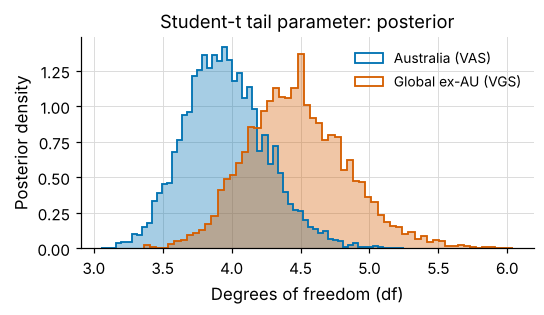

In [12]:
fig, ax = plt.subplots(figsize=(5.0, 3.0))
for k in KEYS:
    dfv = np.exp(mcmc[k][..., 2]).ravel()
    ax.hist(dfv, bins=60, density=True, histtype="stepfilled", alpha=0.35, color=cfg.COLORS[k], lw=0)
    ax.hist(dfv, bins=60, density=True, histtype="step", color=cfg.COLORS[k], lw=1.2, label=cfg.LABELS[k])
ax.set_xlabel("Degrees of freedom (df)")
ax.set_ylabel("Posterior density")
ax.set_title("Student-t tail parameter: posterior")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
gu.savefig(fig, "figB4_t_df")
plt.show()

## 5. Notes for the report

- With the Jeffreys prior, posterior credible intervals and i.i.d. confidence intervals are numerically
  close; the Bayesian contribution is in the probability statements (Section 2), the prior sensitivity, and
  the model checks (Sections 3–4).
- All Bayesian results above assume i.i.d. returns, which notebook 02 rejects (volatility clustering), so the
  posterior uncertainty in the drifts is likely understated. Notebook 03's HAC and block-bootstrap intervals
  address this from the frequentist side.
- `data/clean/posterior_gbm.csv` holds the posterior draws in annual units for notebook 04 (shortfall
  probabilities that integrate over parameter uncertainty).